# Mercedes-Benz: evaluation contracts around a CPU baseline

## TL;DR

The engineering question is whether the delivered predictions come from the evaluated, fold-fitted pipelines. The fixed recipe is a conventional baseline, not a modeling novelty claim.

Two observed conditions justify specific controls: **24 test observations contain categories absent from full training**, and one maximum-target observation contributes **9.79% of baseline squared error**. The first requires defined unknown-category behavior; the second requires transparent error accounting rather than target-row removal.

Appended SVD coordinates slightly improve the fixed blend's R², but worsen Random Forest and slightly worsen blend MAE. The study retains all families and folds, and does not optimize blend weights on the reported OOF labels.

## Questions and approach

Use five fixed shuffled folds, two declared training seeds, three model families and equal weights. Fit all preprocessing inside each training fold. Compare adding 16 SVD coordinates on matched data, folds and budgets; appended coordinates change representation and do not add input information or compress the full input.

## Data sources

The tables and plots below read `docs/data-audit.json` and `docs/modeling-study.json`, which retain source/input/split/config fingerprints from completed real-data runs. Raw rows, IDs and weights are private. An optional final cell independently reloads every native model when local authorized paths are provided.

## Analysis

In [1]:
import json
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

root = Path.cwd() if Path("docs/modeling-study.json").exists() else Path.cwd().parent
audit = json.loads((root / "docs/data-audit.json").read_text())
study = json.loads((root / "docs/modeling-study.json").read_text())
assert study["project_id"] == "mercedes-benz"
base = study["runs"]["baseline"]
projection = study["runs"]["projection"]
print({"train_rows": audit["rows"]["train"], "test_rows": audit["rows"]["test"], "categorical_features": len(audit["categorical_features"]), "numeric_features": audit["numeric_feature_count"], "held_out_once_per_family_seed": audit["rows"]["train"]})

{'train_rows': 4209, 'test_rows': 4209, 'categorical_features': 8, 'numeric_features': 368, 'held_out_once_per_family_seed': 4209}


### 1. Unknown categories are a real delivery condition

The old scripts fit category vocabularies on combined train/test inputs. This maintained pipeline fits training rows only and explicitly maps unseen categories through the fitted encoder's ignore policy. This makes inference behavior defined; it does not establish predictive accuracy on unlabeled new-category observations.

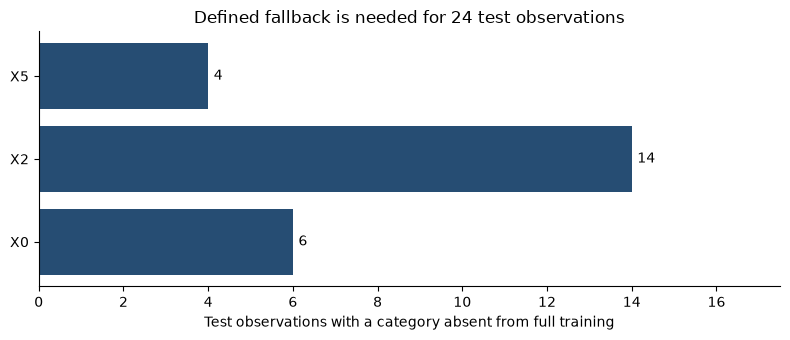

In [2]:
unknown = {key: value["test_rows_unseen"] for key, value in audit["unknown_test_categories"].items() if value["test_rows_unseen"]}
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(list(unknown), list(unknown.values()), color="#264d73")
ax.bar_label(bars, padding=4)
ax.set_xlim(0, max(unknown.values()) * 1.25)
ax.set_xlabel("Test observations with a category absent from full training")
ax.set_title(f"Defined fallback is needed for {audit['test_rows_with_any_unseen_category']} test observations")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### 2. Representation effects depend on the estimator and metric

The 16 projection coordinates are appended to the original encoded features. They can change the regularization geometry seen by Ridge or the directions available to axis-aligned tree splits. A change in R² is not evidence that new data or a compressed representation was added. Compare every family before summarizing the blend.

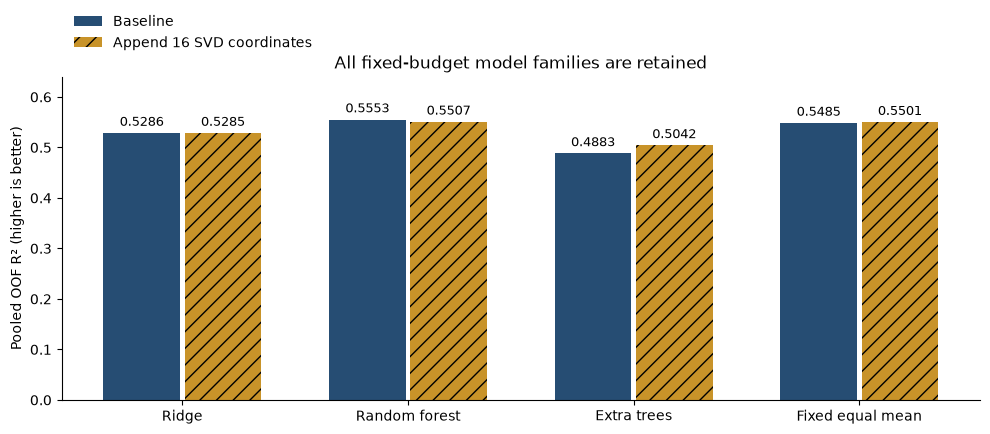

| Fixed blend | R² | RMSE | MAE |
|---|---:|---:|---:|
| Baseline | 0.548490 | 8.518833 | 5.404546 |
| Appended SVD | 0.550070 | 8.503915 | 5.406060 |

In [3]:
keys = ["family:ridge", "family:random_forest", "family:extra_trees", "equal_mean"]
labels = ["Ridge", "Random forest", "Extra trees", "Fixed equal mean"]
x = np.arange(len(keys))
fig, ax = plt.subplots(figsize=(10, 4.5))
for offset, (run, label, color, hatch) in zip([-0.18, 0.18], [(base, "Baseline", "#264d73", None), (projection, "Append 16 SVD coordinates", "#c89329", "//")], strict=True):
    values = [run["results"][key]["pooled"]["r2"] for key in keys]
    bars = ax.bar(x + offset, values, width=0.34, label=label, color=color, hatch=hatch)
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)
ax.set_xticks(x, labels)
ax.set_ylim(0, 0.64)
ax.set_ylabel("Pooled OOF R² (higher is better)")
ax.set_title("All fixed-budget model families are retained")
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.23), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()
rows = ["| Fixed blend | R² | RMSE | MAE |", "|---|---:|---:|---:|"]
for run, label in [(base, "Baseline"), (projection, "Appended SVD")]:
    p = run["results"]["equal_mean"]["pooled"]
    rows.append(f"| {label} | {p['r2']:.6f} | {p['rmse']:.6f} | {p['mae']:.6f} |")
display(Markdown("\n".join(rows)))

### 3. A weaker fold needs diagnosis, not deletion

Pooled R² uses a global target-mean denominator. Mean fold R² averages ratios with different denominators and is a separate descriptive quantity. The maximum-target observation is also the largest baseline residual; it contributes 9.79% of all squared error and 33.63% inside the weakest fold. Target SST concentration and model residual SSE concentration are measured separately. Every observation remains evaluated.

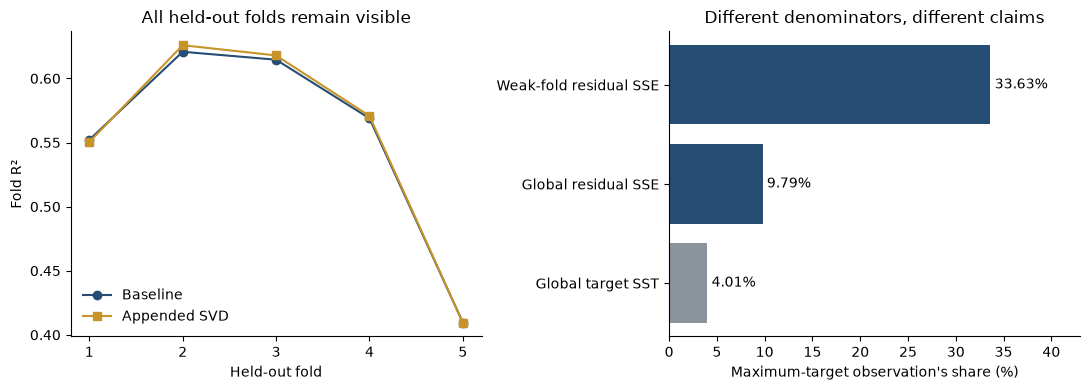

{'pooled_r2': 0.5484900450001697, 'mean_fold_r2': 0.5532123844727782, 'ridge_baseline_seed_prediction_delta': 0.0}


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for run, label, color, marker in [(base, "Baseline", "#264d73", "o"), (projection, "Appended SVD", "#c89329", "s")]:
    folds = run["results"]["equal_mean"]["folds"]
    axes[0].plot([f["fold"] + 1 for f in folds], [f["r2"] for f in folds], marker=marker, label=label, color=color)
axes[0].set(xlabel="Held-out fold", ylabel="Fold R²", title="All held-out folds remain visible", xticks=range(1, 6))
axes[0].legend(frameon=False)
d = base["diagnostics"]
shares = [100 * audit["target"]["top1_squared_deviation_share"], 100 * d["maximum_target_sse_share"], 100 * next(iter(d["maximum_target_within_fold_sse_share"].values()))]
bars = axes[1].barh(["Global target SST", "Global residual SSE", "Weak-fold residual SSE"], shares, color=["#8b939c", "#264d73", "#264d73"])
axes[1].bar_label(bars, fmt="%.2f%%", padding=3)
axes[1].set(xlim=(0, 43), xlabel="Maximum-target observation's share (%)", title="Different denominators, different claims")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()
print({"pooled_r2": base["results"]["equal_mean"]["pooled"]["r2"], "mean_fold_r2": d["mean_fold_r2"], "ridge_baseline_seed_prediction_delta": d["ridge_seed_max_prediction_delta"]})

## Results

The fixed blend is retained as the declared reference even though baseline Random Forest has the stronger observed OOF score. No weights are selected from these labels. The projection comparison has mixed estimator effects and slightly worsens MAE, so it supports a qualified representation finding rather than a universal improvement claim.

## Checks

Set `MERCEDES_DATA_DIR` to authorized inputs and `MERCEDES_RUN_DIR` to a completed native run to reconstruct every saved pipeline. The committed outputs below were generated with the actual baseline run. If those paths are absent, this cell explicitly leaves model reconstruction unperformed for the current notebook execution.

In [5]:
data_dir = os.environ.get("MERCEDES_DATA_DIR")
run_dir = os.environ.get("MERCEDES_RUN_DIR")
if data_dir and run_dir:
    from mercedes.pipeline import evaluate
    reconstruction = evaluate(Path(run_dir), Path(data_dir))
    assert reconstruction["models_reloaded"] == 30
    assert reconstruction["maximum_prediction_delta"] <= reconstruction["tolerance"]
    print(reconstruction)
else:
    print("Aggregate evidence only in this execution; provide authorized data/run paths for independent model reconstruction.")

{'status': 'verified_model_reload', 'models_reloaded': 30, 'maximum_prediction_delta': 7.105427357601002e-14, 'tolerance': 1e-10, 'metrics': {'r2': 0.5484900450001694, 'rmse': 8.518833488638947, 'mae': 5.4045460030451045}, 'test_rows': 4209, 'train_rows': 4209}


## Caveats and next steps

This is record-level random-fold competition validation. Repeated anonymized feature vectors do not prove the same physical vehicle, and these folds do not establish prospective performance on future manufacturing configurations. Ridge's repeated baseline predictions are deterministic, not independent evidence of training stability; the projection pipeline adds randomized representation fitting.

The historical vocabulary, target-median features and OOF blend search differ from this maintained recipe. Modern CV and historical leaderboard scores are separate populations. [Results and score context](../docs/results.md) · [Controlled comparison](../docs/modeling-study.md) · [Consumer handoff](../docs/consumer-contract.md).

The next engineering step is a verified handoff of the exact model/input/output identities, preserving the completed experiment when external delivery fails. A production service, automated retraining and service-level guarantees are outside this project.